# Chest X-Ray Image Classifiaction

In [21]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Path to dataset files: /kaggle/input/chest-xray-pneumonia


### Import Libraries

In [22]:
import numpy as np
import pandas as pd
import os
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
import glob
import seaborn as sns

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, classification_report

from tensorflow.keras.models import Model
from tensorflow.keras.models import load_model
from sklearn.utils import class_weight
from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D, Activation, Dropout, BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

### Data Loading and Preprocessing

In [23]:
train_dir = "/kaggle/input/chest-xray-pneumonia/chest_xray/train"
val_dir = "/kaggle/input/chest-xray-pneumonia/chest_xray/val"
test_dir = "/kaggle/input/chest-xray-pneumonia/chest_xray/test"

In [24]:
data_dir = train_dir
class_names=os.listdir(train_dir)
print(class_names)

['PNEUMONIA', 'NORMAL']


In [25]:
normal = glob.glob("/kaggle/input/chest-xray-pneumonia/chest_xray/train/NORMAL/*.jpeg")
pneumonia = glob.glob("/kaggle/input/chest-xray-pneumonia/chest_xray/train/PNEUMONIA/*.jpeg")

number_of_normal_img_in_train = len(normal)
number_of_pneumonia_img_in_train = len(pneumonia)
number_of_total_img_in_train = len(normal) + len(pneumonia)

normal_val = glob.glob("/kaggle/input/chest-xray-pneumonia/chest_xray/val/NORMAL/*.jpeg")
pneumonia_val = glob.glob("/kaggle/input/chest-xray-pneumonia/chest_xray/val/PNEUMONIA/*.jpeg")

number_of_normal_img_in_val = len(normal_val)
number_of_pneumonia_img_in_val = len(pneumonia_val)
number_of_total_img_in_val = len(normal_val) + len(pneumonia_val)

normal_test = glob.glob("/kaggle/input/chest-xray-pneumonia/chest_xray/test/NORMAL/*.jpeg")
pneumonia_test = glob.glob("/kaggle/input/chest-xray-pneumonia/chest_xray/test/PNEUMONIA/*.jpeg")

number_of_normal_img_in_test = len(normal_test)
number_of_pneumonia_img_in_test = len(pneumonia_test)
number_of_total_img_in_test = len(normal_test) + len(pneumonia_test)

print("Training Data")
print("Normal: ", number_of_normal_img_in_train)
print("Pneumonia:", number_of_pneumonia_img_in_train)
print("Total:", number_of_total_img_in_train)
print()

print("Test Data")
print("Normal:", number_of_normal_img_in_test)
print("Pneumonia:", number_of_pneumonia_img_in_test)
print("Total:", number_of_total_img_in_test)
print()

print("Validation Data")
print("Normal:", number_of_normal_img_in_val)
print("Pneumonia:", number_of_pneumonia_img_in_val)
print("Total:", number_of_total_img_in_val)

Training Data
Normal:  1341
Pneumonia: 3875
Total: 5216

Test Data
Normal: 234
Pneumonia: 390
Total: 624

Validation Data
Normal: 8
Pneumonia: 8
Total: 16


### Visualization

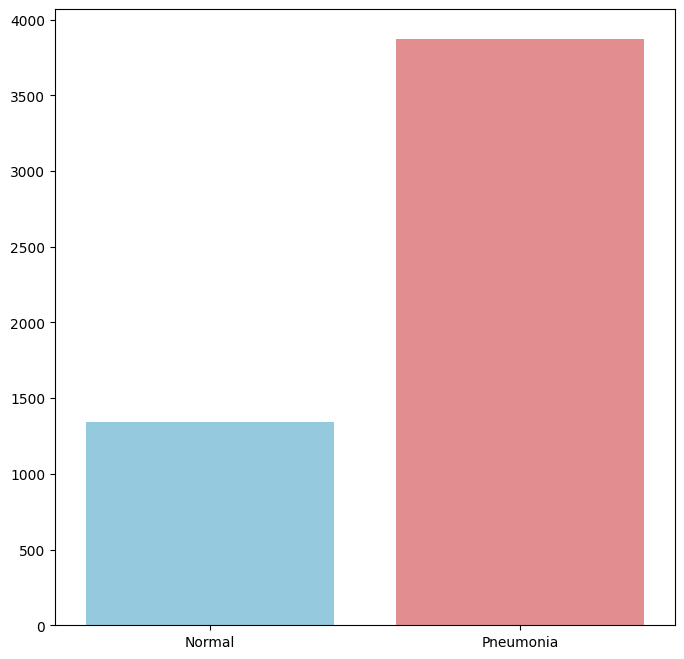

In [26]:
plt.figure(figsize=(8,8))
sns.barplot(x = ['Normal', 'Pneumonia'], y = [number_of_normal_img_in_train, number_of_pneumonia_img_in_train], hue=['Normal', 'Pneumonia'], palette=['skyblue', 'lightcoral'], legend=False);

In [27]:
def show_samples(img_paths, category, num_samples=5):
    plt.figure(figsize=(15, 5))
    for i in range(num_samples):
        img_path = img_paths[i]
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.subplot(1, num_samples, i + 1)
        plt.imshow(img)
        plt.title(category)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

Normal Samples:


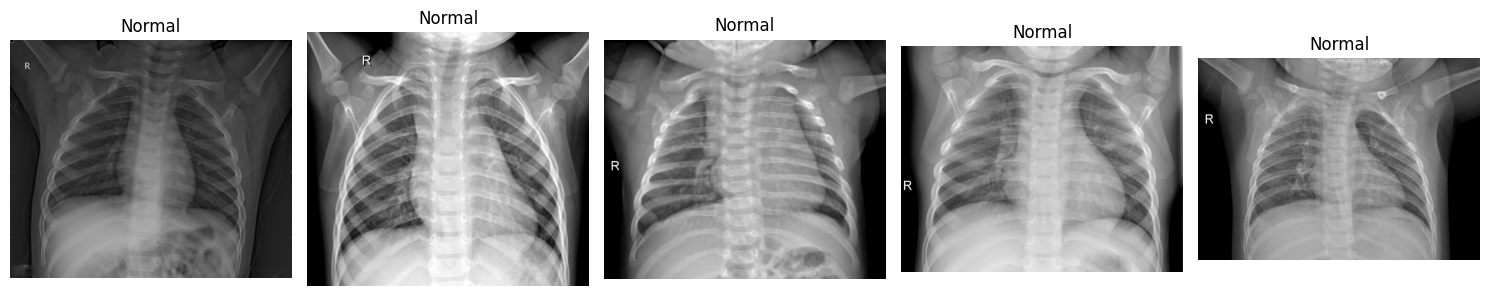



Pneumonia Samples:


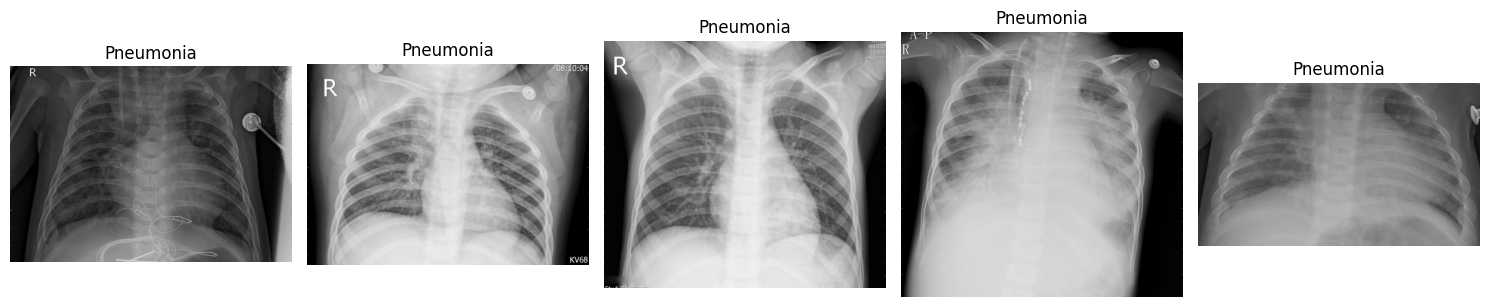

In [28]:
print('Normal Samples:')
show_samples(normal, 'Normal')
print()
print()

print('Pneumonia Samples:')
show_samples(pneumonia, 'Pneumonia')

### Data Augmentation

In [29]:
train_datagen = ImageDataGenerator(
    rescale=1/255,
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True,
    vertical_flip=True,
    fill_mode='nearest',
    samplewise_center=True,
    samplewise_std_normalization=True
)

val_datagen = ImageDataGenerator(
    rescale=1/255,
    samplewise_center=True,
    samplewise_std_normalization=True
)

test_datagen = ImageDataGenerator(
    rescale=1/255,
    samplewise_center=True,
    samplewise_std_normalization=True
)

In [30]:
train = train_datagen.flow_from_directory(
    train_dir,
    batch_size=32,
    target_size=(224,224),
    class_mode = 'binary',
    shuffle = True
)

test = test_datagen.flow_from_directory(
    test_dir,
    batch_size=32,
    target_size=(224,224),
    class_mode = 'binary',
    shuffle = False  # keep order fixed so predictions line up with test.classes
)

val = val_datagen.flow_from_directory(
    val_dir,
    batch_size=32,
    target_size=(224,224),
    class_mode = 'binary',
    shuffle = True
)

Found 5216 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Found 16 images belonging to 2 classes.


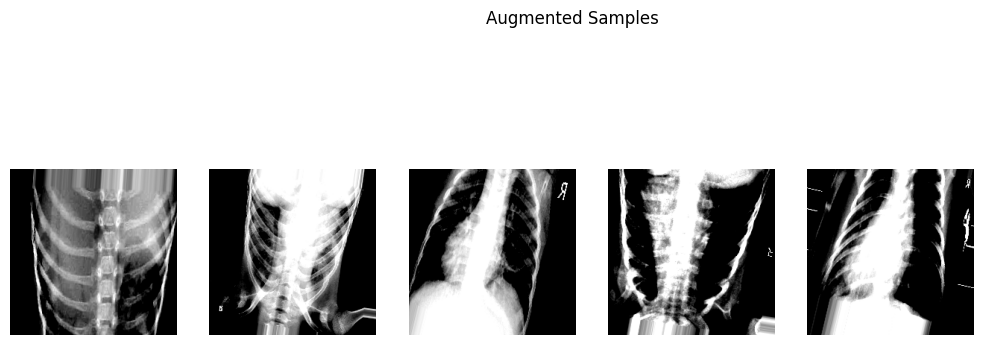

In [31]:
def display_augmented_samples(train_generator, num_samples=5):
    augmented_images, _ = next(train_generator)

    plt.figure(figsize=(15, 5))
    for i in range(num_samples):
        plt.subplot(1, num_samples + 1, i + 1)
        plt.imshow(np.clip(augmented_images[i], 0, 1))
        plt.axis('off')
    plt.suptitle('Augmented Samples')
    plt.show()

display_augmented_samples(train, num_samples=5)

In [32]:
# Get class labels from the training generator
labels = train.labels

# Calculate class weights
class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(labels),
    y=labels
)

# Convert class_weights to a dictionary for Keras
class_weights_dict = dict(enumerate(class_weights))

print("Calculated Class Weights:", class_weights_dict)

Calculated Class Weights: {0: np.float64(1.9448173005219984), 1: np.float64(0.6730322580645162)}


### ResNet50 Model

In [33]:
base_model = ResNet50(weights = 'imagenet', input_shape = (224,224,3) , include_top=False, pooling='avg')

# for l in base_model.layers[:-6]:
#     l.trainable=False

for layer in base_model.layers:
  layer.trainable = False

# Get the output of the base model
x = base_model.output

# Add Batch Normalization
x = BatchNormalization()(x)

# Add a Dense layer with ReLU activation
x = Dense(512, activation='relu')(x)
x = Dense(256, activation='relu')(x)
x = Dense(128, activation='relu')(x)

# Add Dropout for regularization
x = Dropout(0.5)(x) # A common dropout rate is 0.5

# Final output layer for binary classification (Pneumonia vs. Normal)
predictions = Dense(1, activation='sigmoid')(x)

# Create the full model
model = Model(inputs=base_model.input, outputs=predictions)

base_model.summary()

Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 23,587,712 (89.98 MB)

In [34]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall(), tf.keras.metrics.AUC()])

In [35]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

model_checkpoint = ModelCheckpoint(
    'best_model.keras', # Name of the file to save the model in .keras format
    monitor='val_loss', # Metric to monitor
    save_best_only=True, # Save only the best model
    mode='min', # 'min' for loss, 'max' for accuracy
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss', # Metric to monitor
    factor=0.2, # Factor by which the learning rate will be reduced. new_lr = lr * factor
    patience=8, # Number of epochs with no improvement after which learning rate will be reduced.
    min_lr=0.00001, # Lower bound on the learning rate.
    verbose=1
)

history = model.fit(
    train,
    epochs=50, # You can adjust the number of epochs
    validation_data=val,
    callbacks=[early_stopping, model_checkpoint, reduce_lr],
    class_weight=class_weights_dict # Apply class weights here
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 637ms/step - accuracy: 0.7801 - auc_1: 0.8652 - loss: 0.4763 - precision_1: 0.9229 - recall_1: 0.7643
Epoch 1: val_loss improved from inf to 0.59873, saving model to best_model.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 122s 672ms/step - accuracy: 0.7804 - auc_1: 0.8655 - loss: 0.4759 - precision_1: 0.9230 - recall_1: 0.7646 - val_accuracy: 0.7500 - val_auc_1: 0.7422 - val_loss: 0.5987 - val_precision_1: 0.6667 - val_recall_1: 1.0000 - learning_rate: 0.0010
Epoch 2/50
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 630ms/step - accuracy: 0.8451 - auc_1: 0.9303 - loss: 0.3384 - precision_1: 0.9588 - recall_1: 0.8300
Epoch 2: val_loss improved from 0.59873 to 0.54445, saving model to best_model.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 104s 637ms/step - accuracy: 0.8452 - auc_1: 0.9303 - loss: 0.3383 - precision_1: 0.9588 - recall_1: 0.8301 - val_accuracy: 0.7500 - val_auc_1: 0.8594 - val_loss: 0.5444 - val_precision_1: 0.7000 - val_recall_1: 0.8750 - learning_rate: 0.0010
Ep

### Model Evaluation

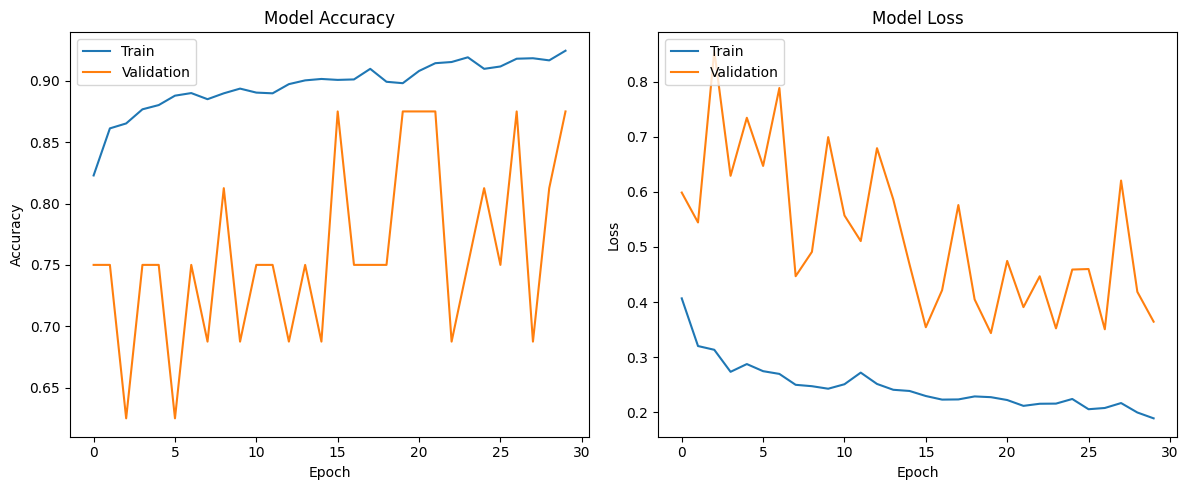

In [36]:
import matplotlib.pyplot as plt

# Plot training & validation accuracy values
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.tight_layout()
plt.show()

In [37]:
# Evaluating the model on train and test
score = model.evaluate(train)

print("Train Loss: ", score[0])
print("Train Accuracy: ", score[1])

score = model.evaluate(test)
print("\nTest loss: ", score[0])
print("Test Accuracy: ", score[1])

163/163 ━━━━━━━━━━━━━━━━━━━━ 108s 645ms/step - accuracy: 0.9014 - auc_1: 0.9772 - loss: 0.2344 - precision_1: 0.9872 - recall_1: 0.8776
Train Loss:  0.2511918246746063
Train Accuracy:  0.8997315764427185


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 264ms/step - accuracy: 0.8304 - auc_1: 0.8901 - loss: 0.4279 - precision_1: 0.8325 - recall_1: 0.9048

Test loss:  0.3812554180622101
Test Accuracy:  0.8509615659713745


In [38]:
# Load the best model saved during training
model = load_model('best_model.keras')

print("Evaluating model on test data...")
loss, accuracy, precision, recall, auc = model.evaluate(train)

print(f"Train Loss: {loss:.4f}")
print(f"Train Accuracy: {accuracy:.4f}")
print(f"Train Precision: {precision:.4f}")
print(f"Train Recall: {recall:.4f}")
print(f"Train AUC: {auc:.4f}")
print()

print("Evaluating model on test data...")
loss, accuracy, precision, recall, auc = model.evaluate(test)

print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test AUC: {auc:.4f}")

Evaluating model on test data...
163/163 ━━━━━━━━━━━━━━━━━━━━ 111s 641ms/step - accuracy: 0.8978 - auc_1: 0.9799 - loss: 0.2384 - precision_1: 0.9908 - recall_1: 0.8708
Train Loss: 0.2449
Train Accuracy: 0.8926
Train Precision: 0.9897
Train Recall: 0.8645
Train AUC: 0.9781

Evaluating model on test data...
20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 384ms/step - accuracy: 0.8587 - auc_1: 0.9222 - loss: 0.3395 - precision_1: 0.8864 - recall_1: 0.8945
Test Loss: 0.3813
Test Accuracy: 0.8510
Test Precision: 0.8722
Test Recall: 0.8923
Test AUC: 0.9083


### Classification Report

In [ ]:

# Get predictions for the test set
print("Generating predictions for classification report...")
y_pred_prob = model.predict(test)
y_pred = (y_pred_prob > 0.5).astype(int)

# Get true labels from the test generator
y_true = test.classes

# Get class names from the test generator
class_names = list(test.class_indices.keys())
# Generate and print the classification report
from sklearn.metrics import classification_report

print("Classification Report:")
print()

print(classification_report(y_true, y_pred, target_names=class_names))

### Save Model

In [40]:
model.save('pneumonia_detection_model.keras')

### Testing

In [41]:
loaded_model = tf.keras.models.load_model('pneumonia_detection_model.keras')
print("Model 'pneumonia_detection_model.keras' loaded successfully.")

Model 'pneumonia_detection_model.keras' loaded successfully.


In [42]:
from google.colab import files

# 1. Upload an image file
print("Please upload an image file (e.g., JPEG, PNG).")
uploaded = files.upload()

# Process the uploaded image
for fn in uploaded.keys():
    # 2. Store the uploaded file content
    img_bytes = uploaded[fn]

    # 3. Convert the uploaded image content into a NumPy array
    img_array = np.frombuffer(img_bytes, np.uint8)

    # 4. Decode the image array using cv2.imdecode
    img = cv2.imdecode(img_array, cv2.IMREAD_COLOR)

    # 5. Convert the image from BGR to RGB format
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # 6. Resize the image to (224, 224) pixels
    img = cv2.resize(img, (224, 224))

    # 7. Convert the image to a float32 data type
    img = img.astype(np.float32)

    # 8. Normalize the image
    # Rescale pixel values by dividing by 255.0
    img = img / 255.0
    # Apply sample-wise centering (subtract the mean)
    mean = np.mean(img)
    img = img - mean
    # Apply sample-wise standard deviation normalization (divide by the standard deviation)
    std = np.std(img)
    # Avoid division by zero if std is very small
    if std == 0:
        std = 1e-7
    img = img / std

    # 9. Expand the dimensions of the preprocessed image to add a batch dimension
    input_image = np.expand_dims(img, axis=0)

    print(f"Image '{fn}' uploaded and preprocessed successfully. Shape: {input_image.shape}")
    break # Assuming only one image is uploaded for prediction


Please upload an image file (e.g., JPEG, PNG).


Saving 332aa0c67cb2e035e372c7cb3ceca2_big_gallery.jpg to 332aa0c67cb2e035e372c7cb3ceca2_big_gallery.jpg
Image '332aa0c67cb2e035e372c7cb3ceca2_big_gallery.jpg' uploaded and preprocessed successfully. Shape: (1, 224, 224, 3)


In [43]:
prediction = loaded_model.predict(input_image)
probability = prediction[0][0]

# Define class labels
class_labels = {0: 'NORMAL', 1: 'PNEUMONIA'}

# Determine the predicted class and its probability
if probability > 0.5:
    predicted_class = class_labels[1]
    confidence = probability
else:
    predicted_class = class_labels[0]
    confidence = 1 - probability

print(f"Prediction: {predicted_class} (Confidence: {confidence:.2f})")


1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
Prediction: NORMAL (Confidence: 1.00)


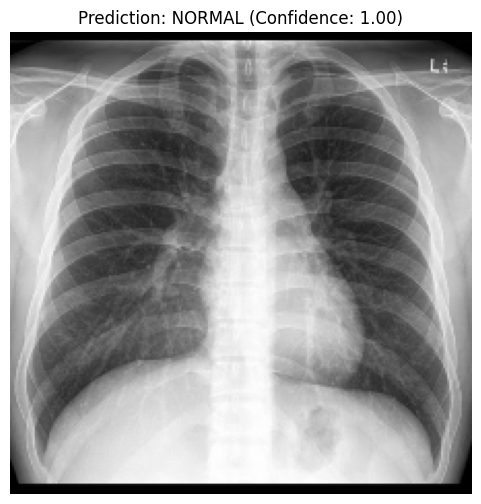

In [44]:
import matplotlib.pyplot as plt

# Re-process the uploaded image for display purposes (without normalization)
for fn in uploaded.keys():
    img_bytes_display = uploaded[fn]
    img_array_display = np.frombuffer(img_bytes_display, np.uint8)
    img_display = cv2.imdecode(img_array_display, cv2.IMREAD_COLOR)
    img_display = cv2.cvtColor(img_display, cv2.COLOR_BGR2RGB)
    img_display = cv2.resize(img_display, (224, 224))
    break # Assuming only one image was uploaded

plt.figure(figsize=(6, 6))
plt.imshow(img_display)
plt.title(f"Prediction: {predicted_class} (Confidence: {confidence:.2f})")
plt.axis('off')
plt.show()
